# 01 – Data Exploration

In this notebook we **check and look at** the X-ray images.

Steps:
1. Clean the data (remove broken and duplicate images)
2. Count the images
3. Look at some images
4. Check image sizes and colors

## Setup
`sys.path.append("..")` lets the notebook find the `src` folder (one folder up).

In [1]:
import sys
sys.path.append("..")

from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image

from src import config
from src.data_check import run_all

## Step 1 – Clean the data
`run_all()` checks every image in the original folder (`Chest_X-ray`) and copies
only the good ones to `data/processed/`.

The original folder is **not changed**.

Run this again every time you download new data.

In [2]:
counts = run_all()

Step 1: finding images ...
Step 2: removing empty and broken images ...


Step 3: removing duplicates ...


Step 4: copying ...


Copying 15562 images to /Users/vivek/Desktop/Alzaimer-AgenticAI/chest-xray-pneumonia/data/processed ...


Step 5: counting ...

DATA CHECK REPORT
Source: the original Training, Validation and Testing folders

Empty or broken images removed: 0
Duplicate images removed:       38

Images in each part:
  Training
    Covid-19        2699
    Normal          2697
    Pneumonia       2688
    Tuberculosis    2693
  Validation
    Covid-19         500
    Normal           500
    Pneumonia        494
    Tuberculosis     500
  Testing
    Covid-19         700
    Normal           700
    Pneumonia        693
    Tuberculosis     698

Saved: /Users/vivek/Desktop/Alzaimer-AgenticAI/chest-xray-pneumonia/outputs/logs/data_report.txt
Saved: /Users/vivek/Desktop/Alzaimer-AgenticAI/chest-xray-pneumonia/outputs/logs/removed_files.txt


## Step 2 – Count the images
A bar chart of how many good images each disease has, in each folder.
Fair data = bars of about the same height.

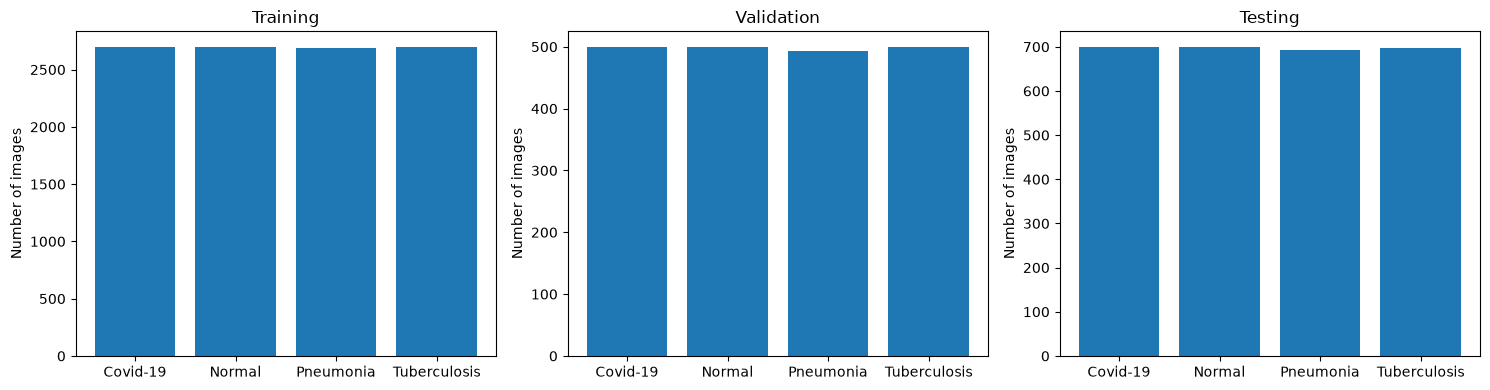

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, split in zip(axes, config.SPLITS):
    numbers = []
    for class_name in config.CLASS_NAMES:
        numbers.append(counts[split][class_name])

    ax.bar(config.CLASS_NAMES, numbers)
    ax.set_title(split)
    ax.set_ylabel("Number of images")

plt.tight_layout()
plt.show()

## Step 3 – Look at some images
5 images from each disease, from the clean **Training** folder.
Check with your eyes: do they look like real chest X-rays?

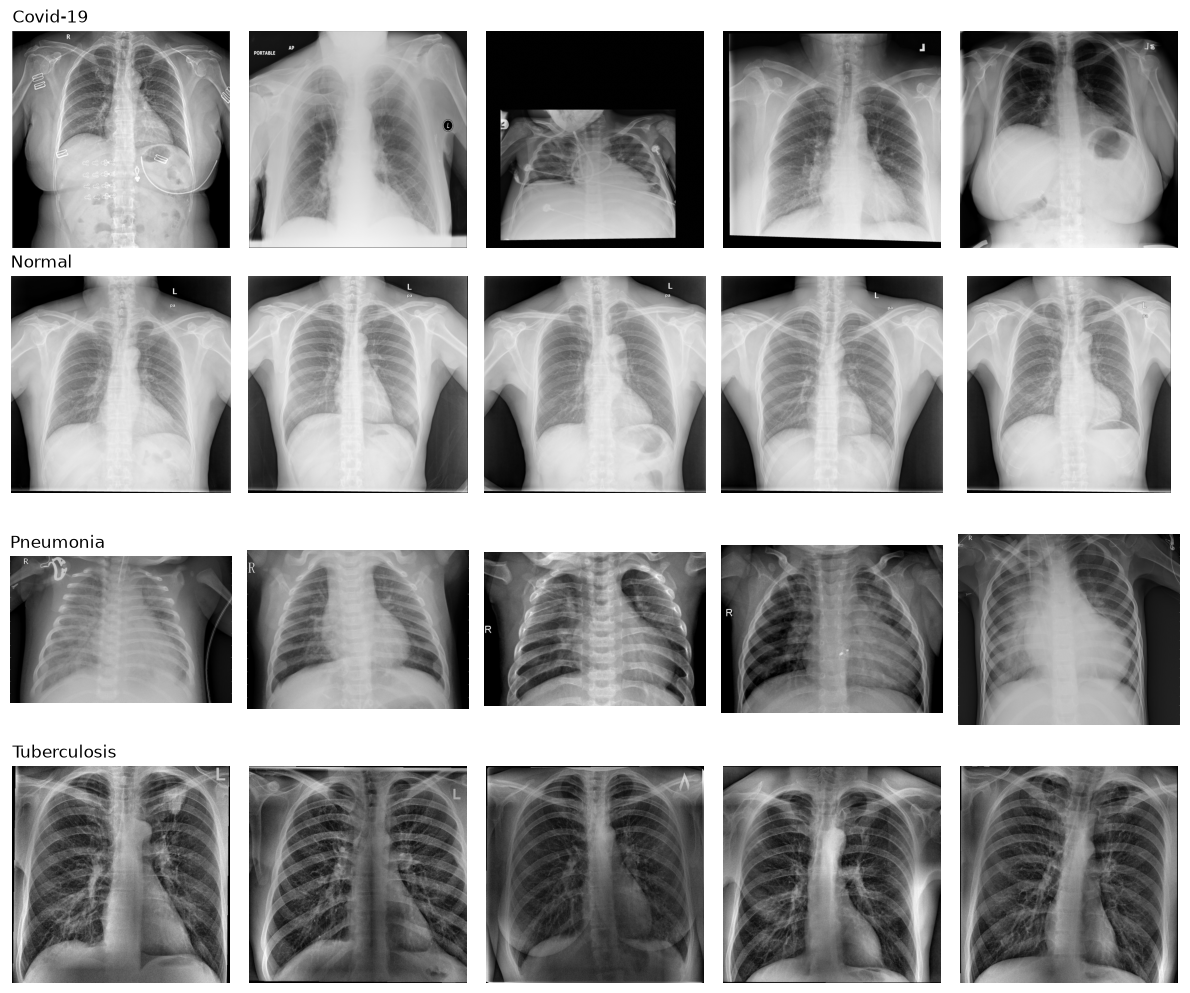

In [4]:
fig, axes = plt.subplots(len(config.CLASS_NAMES), 5, figsize=(12, 10))

for row, class_name in enumerate(config.CLASS_NAMES):
    folder = config.TRAIN_DIR / class_name
    paths = sorted(folder.glob("*"))[:5] if folder.exists() else []

    for col in range(5):
        ax = axes[row, col]
        ax.axis("off")
        if col < len(paths):
            img = Image.open(paths[col])
            ax.imshow(img, cmap="gray")
        if col == 0:
            ax.set_title(class_name if paths else class_name + " (no images)", loc="left")

plt.tight_layout()
plt.show()

## Step 3b – Compare the 4 diseases side by side
Each **column** is one disease. Each **row** shows one example of each disease,
so you can compare them easily.

What to look for:
- **Normal**: the lungs look **dark and clear**. You can see the ribs well.
- **Pneumonia**: **white, cloudy patches** in the lungs (often on one side).
- **Covid-19**: **hazy, gray "ground glass"** areas, often on **both** sides and in the lower lungs.
- **Tuberculosis**: patches, spots or small holes (cavities), often in the **upper** lungs.

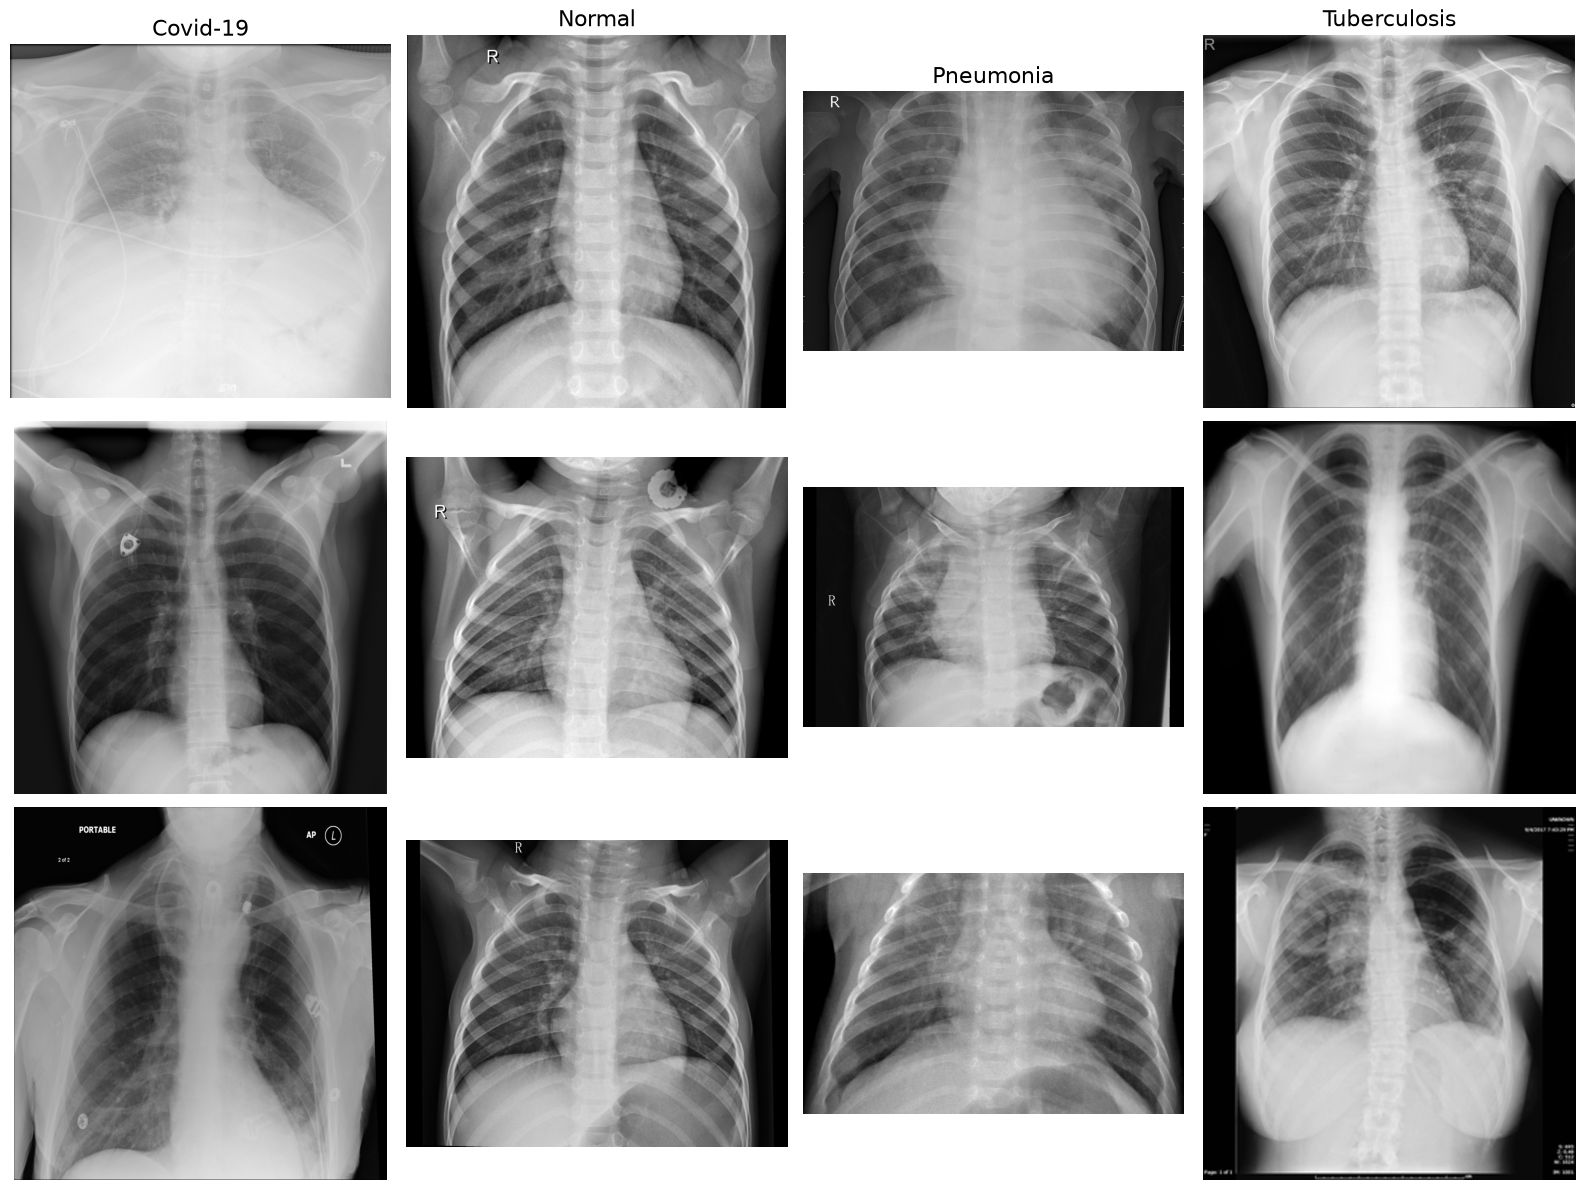

In [5]:
import random

random.seed(config.SEED)  # same photos every time
number_of_rows = 3

fig, axes = plt.subplots(number_of_rows, len(config.CLASS_NAMES), figsize=(16, 12))

for col, class_name in enumerate(config.CLASS_NAMES):
    folder = config.TRAIN_DIR / class_name
    all_paths = sorted(folder.glob("*"))
    chosen = random.sample(all_paths, number_of_rows)  # pick 3 random photos

    for row in range(number_of_rows):
        ax = axes[row, col]
        img = Image.open(chosen[row]).convert("L")  # "L" = show all photos in gray
        ax.imshow(img, cmap="gray")
        ax.axis("off")
        if row == 0:
            ax.set_title(class_name, fontsize=16)

plt.tight_layout()
plt.show()

## Step 4 – Check sizes and colors
- **Size** = width × height in pixels
- **Color mode**: `L` = gray, `RGB` = color, `P` = color with a palette

Different sizes and colors are okay. `preprocessing.py` will make them all
224 × 224 and RGB.

In [6]:
sizes = Counter()
modes = Counter()

for split in config.SPLITS:
    for class_name in config.CLASS_NAMES:
        folder = config.CLEAN_DIR / split / class_name
        if not folder.exists():
            continue
        for path in folder.glob("*"):
            with Image.open(path) as img:
                sizes[img.size] += 1
                modes[img.mode] += 1

print("Color modes:")
for mode, number in modes.most_common():
    print(f"  {mode:<5} {number}")

print()
print("Most common sizes (width, height):")
for size, number in sizes.most_common(5):
    print(f"  {size}  {number}")

print()
print(f"Number of different sizes: {len(sizes)}")

Color modes:
  L     11532
  RGB   3426
  P     604

Most common sizes (width, height):
  (512, 512)  5525
  (1024, 1024)  1740
  (1024, 839)  321
  (1024, 852)  317
  (1024, 843)  172

Number of different sizes: 5285
